# **Land vs. Offshore Analysis**
## Aggregated production

This notebook contains code to generate a chart showing **monthly aggregated production, dividing the series into land and offshore production.**

In [1]:
# Import libraries
import pandas as pd
import os
import matplotlib.pyplot as plt
from matplotlib import lines

In [2]:
# Load data (well inventory and well-level production data)
PATH = os.path.join('..', '..', 'data')
df_inventory = pd.read_csv(PATH+'/oil_intermediate/02_well_inventory.csv')
df_oil_prod = (
    pd
    .read_csv(
        PATH+'/oil_intermediate/01_oil_prod.csv',
        usecols=['fecha', 'nombre_pozo', 'petroleo_mbd'],
        dtype={
            'fecha':str,
            'nombre_pozo':str,
            'petroleo_mbd':float
        }
    )
)

# Parse date column in the production dataframe
df_oil_prod['fecha'] = pd.to_datetime(df_oil_prod['fecha'], format='%Y-%m-%d')

**Fisrt**, break the well-level production into two dataframes:

1. **Land well-level production.**
2. **Offshore well-level production.**

In [3]:
# Filter wells from the well-level production dataframe
land_wells_list = df_inventory.query('ubicacion == "TERRESTRE"')['nombre_pozo'].tolist()
offshore_wells_list = df_inventory.query('ubicacion == "AGUAS SOMERAS"')['nombre_pozo'].tolist()
df_land = df_oil_prod[df_oil_prod['nombre_pozo'].isin(land_wells_list)].copy()
df_offshore = df_oil_prod[df_oil_prod['nombre_pozo'].isin(offshore_wells_list)].copy()

In [4]:
# Monthly production series
monthly_prod_land = (
    df_land
    .groupby(['fecha'], as_index=False).
    agg(
        monthly_prod=('petroleo_mbd', 'sum')
    )
)

monthly_prod_offshore = (
    df_offshore
    .groupby(['fecha'], as_index=False).
    agg(
        monthly_prod=('petroleo_mbd', 'sum')
    )
)

**Second,** create a stackplot chart to show both series between 2000 and 2018

In [5]:
# Filter observations between 2000-2018
land_series = monthly_prod_land[(monthly_prod_land['fecha']>'1999-12-01') & (monthly_prod_land['fecha']<'2019-01-01')]['monthly_prod']
offshore_series = monthly_prod_offshore[(monthly_prod_offshore['fecha']>'1999-12-01') & (monthly_prod_offshore['fecha']<'2019-01-01')]['monthly_prod']

# Month series
month_series = [x for x in range(1,229)]

In [6]:
# Year labels for x-axis labels
x_labels = []

for i in range(2000, 2020, 2):

    l = f'{i}'
    x_labels.append(l)

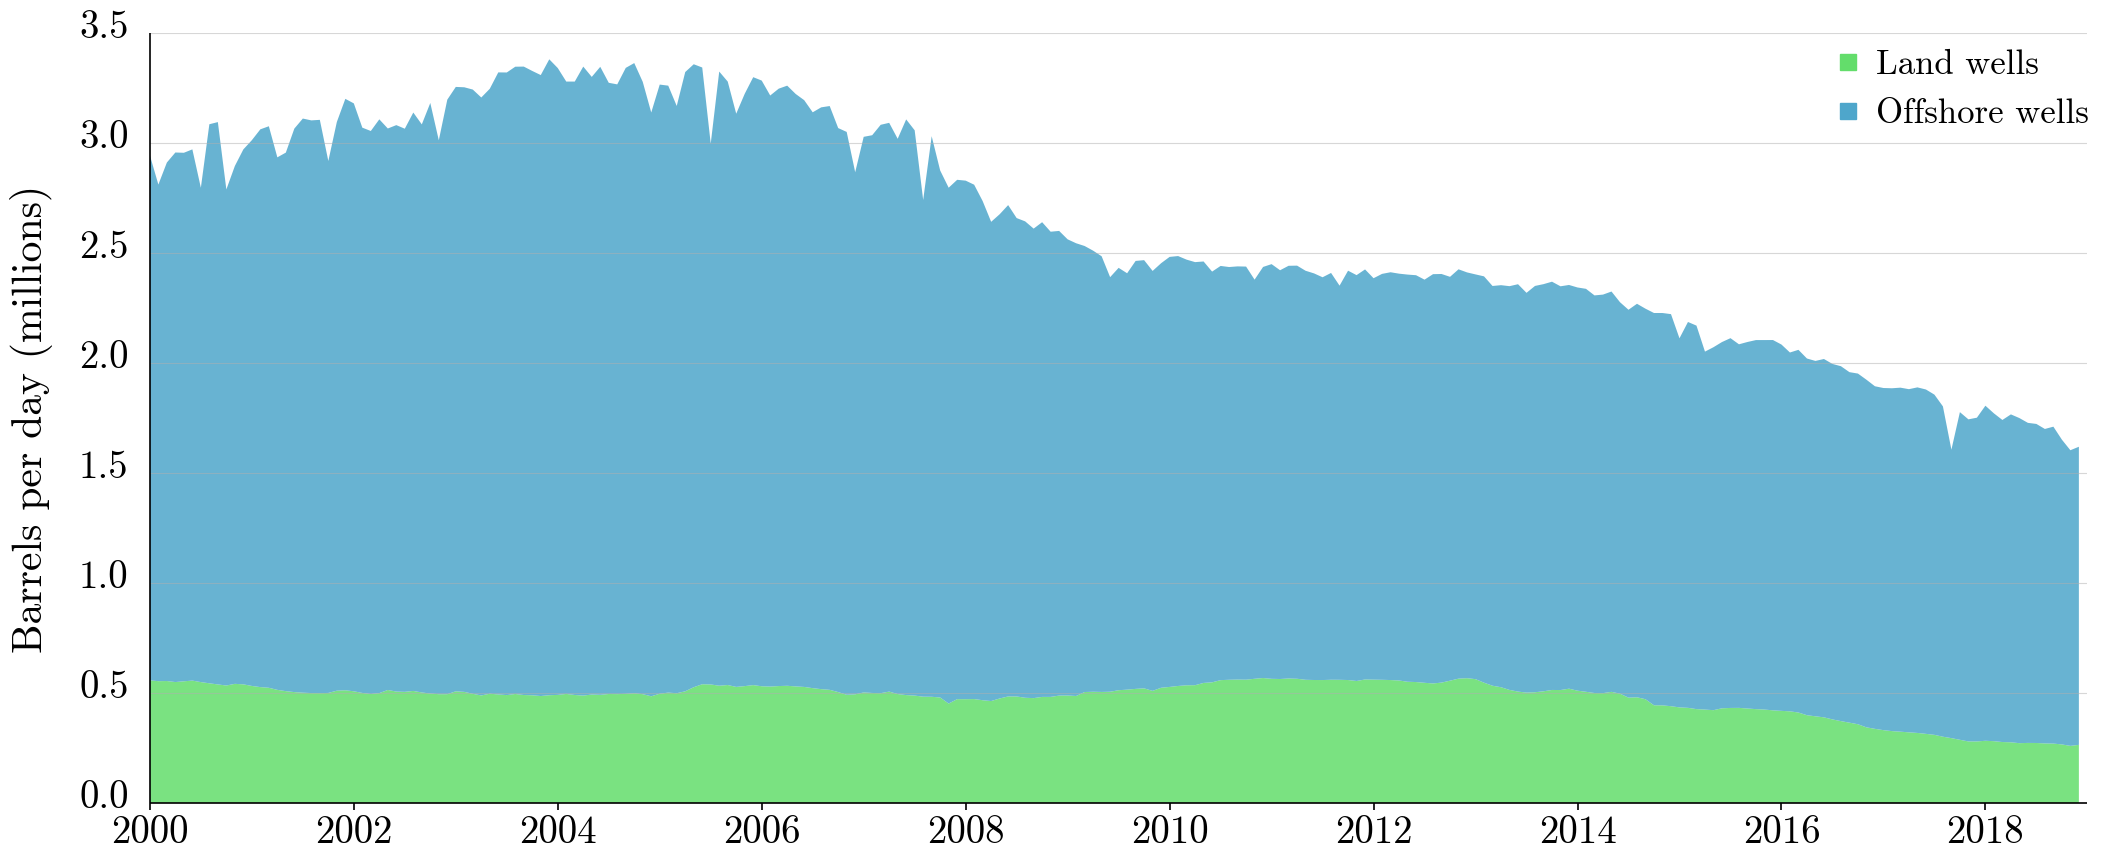

In [69]:
# Create subplots object
fig, ax = plt.subplots(figsize=(25,10))

# Y-axis settings
ax.set_ylim(0, 3500)
ax.set_ylabel('Barrels per day (millions)', fontsize=30, fontweight=100, fontfamily="cmr10") # <- Axis name label
ax.yaxis.set_label_coords(-0.050, 0.5)
ax.yaxis.set_tick_params(labelleft=False, length=0)

# Y-axis labels
for i in range(0,3501,500):

    ax.text(
        -1.5, i-20, f'{i/1000:,.1f}', 
        ha="right", va="baseline", fontsize=28,
        fontfamily="cmr10", fontweight=100
    )

# X-axis settings
ax.set_xlim(1, 229)
ax.xaxis.set_ticks(list(range(1, 229, 24)))
ax.xaxis.set_ticklabels(x_labels, fontsize=28, fontweight=100, fontfamily="cmr10")
ax.xaxis.set_tick_params(length=5, width=1.2)

# Spine settings
ax.spines["bottom"].set_lw(1.2)
ax.spines["bottom"].set_capstyle("butt")
ax.spines['left'].set_lw(1.2)
ax.spines['left'].set_capstyle("butt")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# Series
ax.stackplot(
    month_series,
    land_series,
    offshore_series,
    labels=["Land", "Offshore"],
    colors=["#63DD6B", "#4EA6CB"],
    alpha=0.85,
)

# Grid settings
ax.grid(axis='y', alpha=0.5)

# Legend settings
legend_handles = [
    lines.Line2D([0],[0], marker='s', markersize=12, color='none', markerfacecolor="#63DD6B", markeredgecolor="#63DD6B", label="Land wells"),
    lines.Line2D([0],[0], marker='s', markersize=12, color='none', markerfacecolor="#4EA6CB", markeredgecolor="#4EA6CB", label="Offshore wells")
]

ax.legend(
    handles=legend_handles,
    loc="upper left",
    bbox_to_anchor=(0.86, 1.02),
    bbox_transform=ax.transAxes,
    frameon=False,
    ncol=1,
    handlelength=0.01,
    columnspacing=1.5,
    prop={"family": "cmr10", "size": 25}
)

# Tight layout
#fig.tight_layout()

# Show plot
plt.show()